# Complex Wishart MP-PCA Denoising

Complex-valued multi-echo GRE 데이터를 직접 사용하고, 각 local patch의 Hermitian covariance eigenvalue에 대해 finite-size Complex Wishart 최대 고유값 분포를 이용하여 noise component를 분류하는 실험적 MP-PCA 방식이다.

이 노트북은 `complex_wishart_mppca.py`를 불러와 10%, 30%, 50% noisy data를 순차적으로 처리한다.


In [2]:
import os
import gc
from pathlib import Path

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

from complex_wishart_mppca import complex_wishart_mppca


### 환경설정


In [4]:
NOISE_LEVELS = [10, 30, 50]
PATCH_R = 2
ALPHA = 0.99

NOISY_DIR = Path("./data/noisy_data")
OUT_DIR = Path("./data/denoised/complex_wishart")

OUT_DIR.mkdir(parents=True, exist_ok=True)


### 1. 원본 데이터 불러오기


In [6]:
orig_data = sio.loadmat(
    "./data/meas_gre_dir1.mat",
    simplify_cells=True
)

meas_gre = orig_data["meas_gre"]

print("Original shape :", meas_gre.shape)
print("Original dtype :", meas_gre.dtype)
print("Is complex     :", np.iscomplexobj(meas_gre))


Original shape : (256, 224, 176, 6)
Original dtype : complex128
Is complex     : True


### 2. Noise 데이터 불러오기 및 Complex signal 생성


In [8]:
noisy_datasets = {}

for noise_level in NOISE_LEVELS:
    noisy_path = (
        NOISY_DIR /
        f"noisy_meas_gre_dir1_{noise_level}.mat"
    )

    noisy_data = sio.loadmat(
        noisy_path,
        simplify_cells=True
    )

    noisy_real = noisy_data["noisy_real"].astype(np.float32)
    noisy_imag = noisy_data["noisy_imag"].astype(np.float32)
    mask = noisy_data["mask_brain"].astype(bool)

    noisy_complex = (
        noisy_real.astype(np.complex64)
        + 1j * noisy_imag.astype(np.complex64)
    )

    noisy_datasets[noise_level] = {
        "noisy_complex": noisy_complex,
        "mask": mask,
        "metadata": noisy_data
    }

    print("\n" + "=" * 50)
    print(f"Noise level : {noise_level}%")
    print("Complex shape :", noisy_complex.shape)
    print("Complex dtype :", noisy_complex.dtype)
    print("Is complex    :", np.iscomplexobj(noisy_complex))
    print("=" * 50)



Noise level : 10%
Complex shape : (256, 224, 176, 6)
Complex dtype : complex64
Is complex    : True

Noise level : 30%
Complex shape : (256, 224, 176, 6)
Complex dtype : complex64
Is complex    : True

Noise level : 50%
Complex shape : (256, 224, 176, 6)
Complex dtype : complex64
Is complex    : True


### 3. Complex Wishart MP-PCA Denoising


In [10]:
denoised_data = {}

for noise_level in NOISE_LEVELS:
    noisy_complex = noisy_datasets[noise_level]["noisy_complex"]
    mask = noisy_datasets[noise_level]["mask"]

    print("\n" + "=" * 60)
    print(f"Noise level : {noise_level}%")
    print("Complex Wishart MP-PCA denoising")
    print(f"Patch radius : {PATCH_R}")
    print(f"Alpha        : {ALPHA}")
    print("=" * 60)

    deno_complex, sigma_map, ncomp_map = complex_wishart_mppca(
        noisy_complex,
        mask=mask,
        patch_radius=PATCH_R,
        alpha=ALPHA,
        return_sigma=True,
        return_ncomps=True
    )

    denoised_data[noise_level] = {
        "deno_complex": deno_complex,
        "sigma_map": sigma_map,
        "ncomp_map": ncomp_map
    }

    print("Output shape :", deno_complex.shape)
    print("Output dtype :", deno_complex.dtype)
    print("Is complex   :", np.iscomplexobj(deno_complex))
    print("Mean sigma   :", float(np.mean(sigma_map[mask])))
    print("Mean ncomp   :", float(np.mean(ncomp_map[mask])))
    print(f"{noise_level}% 완료")



Noise level : 10%
Complex Wishart MP-PCA denoising
Patch radius : 2
Alpha        : 0.99
Output shape : (256, 224, 176, 6)
Output dtype : complex64
Is complex   : True
Mean sigma   : 0.4684683680534363
Mean ncomp   : 1.8695898056030273
10% 완료

Noise level : 30%
Complex Wishart MP-PCA denoising
Patch radius : 2
Alpha        : 0.99
Output shape : (256, 224, 176, 6)
Output dtype : complex64
Is complex   : True
Mean sigma   : 1.3079705238342285
Mean ncomp   : 1.1020182371139526
30% 완료

Noise level : 50%
Complex Wishart MP-PCA denoising
Patch radius : 2
Alpha        : 0.99
Output shape : (256, 224, 176, 6)
Output dtype : complex64
Is complex   : True
Mean sigma   : 2.168808937072754
Mean ncomp   : 0.6985839605331421
50% 완료


### 4. 결과 저장


In [12]:
for noise_level in NOISE_LEVELS:
    meta = noisy_datasets[noise_level]["metadata"]
    result = denoised_data[noise_level]

    output_path = (
        OUT_DIR /
        f"denoised_complex_wishart_{noise_level}_r{PATCH_R}_a{ALPHA}.mat"
    )

    save_data = {
        "denoised_complex": result["deno_complex"],
        "sigma_map": result["sigma_map"],
        "ncomp_map": result["ncomp_map"],
        "mask_brain": meta["mask_brain"],
        "noise_level": noise_level,
        "patch_radius": PATCH_R,
        "alpha": ALPHA,
    }

    for key in ["te_gre", "delta_TE", "voxel_size_gre", "B0_dir", "CF"]:
        if key in meta:
            save_data[key] = meta[key]

    sio.savemat(
        output_path,
        save_data
    )

    print("저장 완료 →", output_path)


저장 완료 → data\denoised\complex_wishart\denoised_complex_wishart_10_r2_a0.99.mat
저장 완료 → data\denoised\complex_wishart\denoised_complex_wishart_30_r2_a0.99.mat
저장 완료 → data\denoised\complex_wishart\denoised_complex_wishart_50_r2_a0.99.mat


### 5. Magnitude 시각화


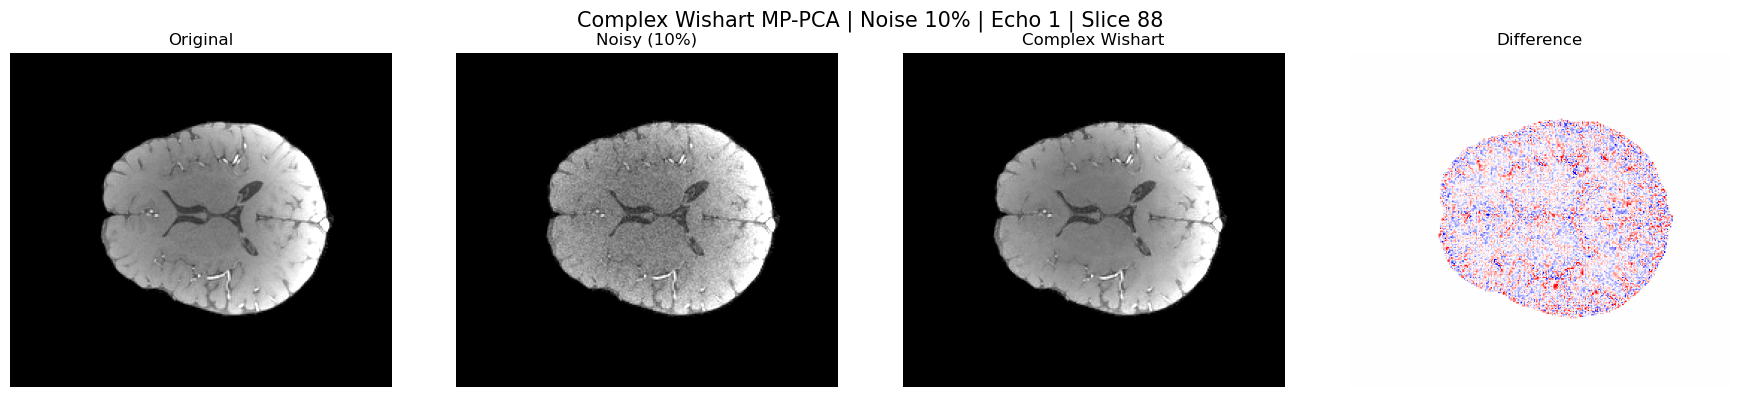

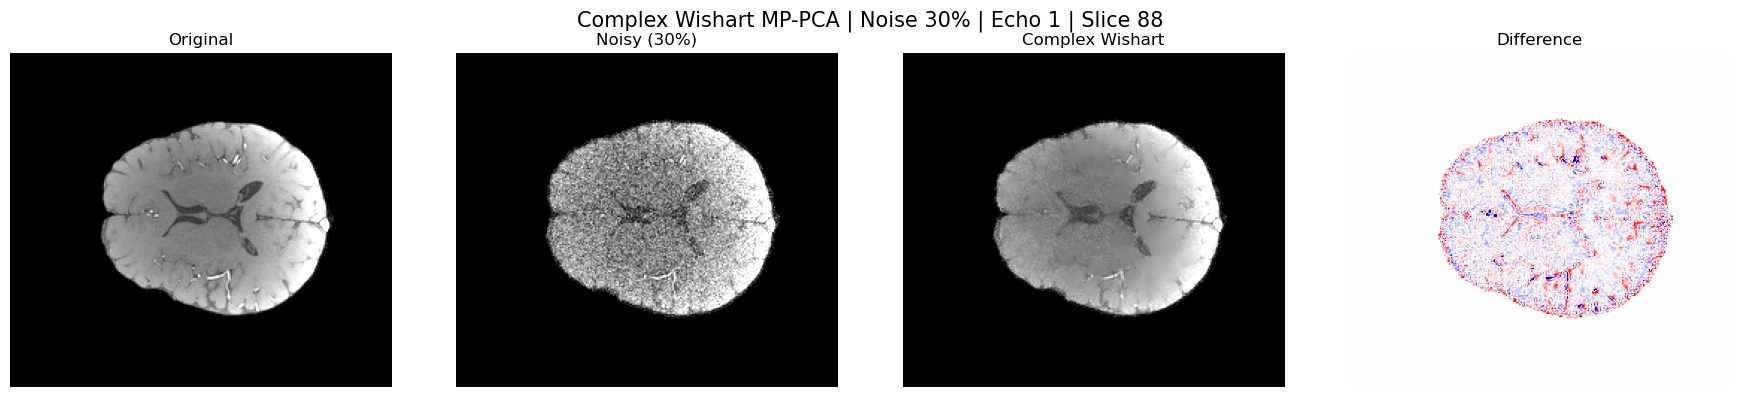

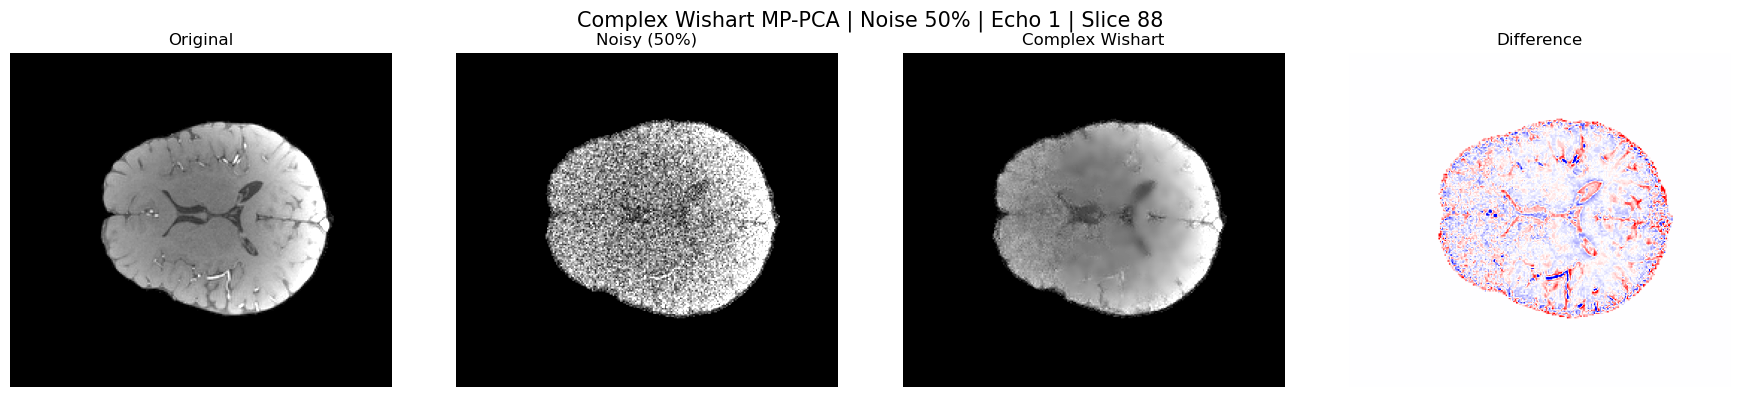

In [14]:
orig_mag = np.abs(meas_gre).astype(np.float32)

echo_idx = 0
slice_idx = meas_gre.shape[2] // 2

for noise_level in NOISE_LEVELS:
    noisy_complex = noisy_datasets[noise_level]["noisy_complex"]
    deno_complex = denoised_data[noise_level]["deno_complex"]
    mask = noisy_datasets[noise_level]["mask"]

    noisy_mag = np.abs(noisy_complex).astype(np.float32)
    deno_mag = np.abs(deno_complex).astype(np.float32)

    orig_2d = orig_mag[:, :, slice_idx, echo_idx]
    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    deno_2d = deno_mag[:, :, slice_idx, echo_idx]

    mask_2d = mask[:, :, slice_idx]
    diff_2d = deno_2d - orig_2d

    vmin, vmax = np.percentile(
        orig_mag[mask],
        (1, 99)
    )

    dv = np.percentile(
        np.abs(diff_2d[mask_2d]),
        99
    )

    fig, ax = plt.subplots(
        1,
        4,
        figsize=(18, 4)
    )

    ax[0].imshow(
        orig_2d.T,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax[0].set_title("Original")
    ax[0].axis("off")

    ax[1].imshow(
        noisy_2d.T,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax[1].set_title(f"Noisy ({noise_level}%)")
    ax[1].axis("off")

    ax[2].imshow(
        deno_2d.T,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )
    ax[2].set_title("Complex Wishart")
    ax[2].axis("off")

    ax[3].imshow(
        diff_2d.T,
        cmap="bwr",
        origin="lower",
        vmin=-dv,
        vmax=dv
    )
    ax[3].set_title("Difference")
    ax[3].axis("off")

    fig.suptitle(
        f"Complex Wishart MP-PCA | Noise {noise_level}% | "
        f"Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


### 6. Sigma map / Retained component map 확인


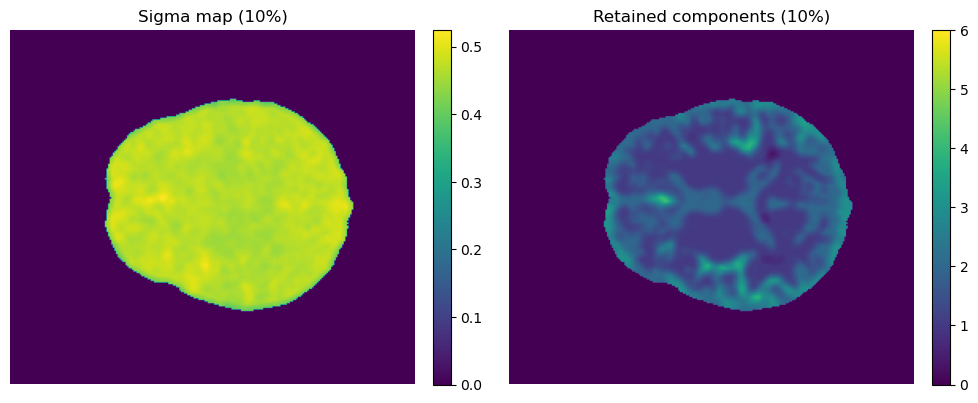

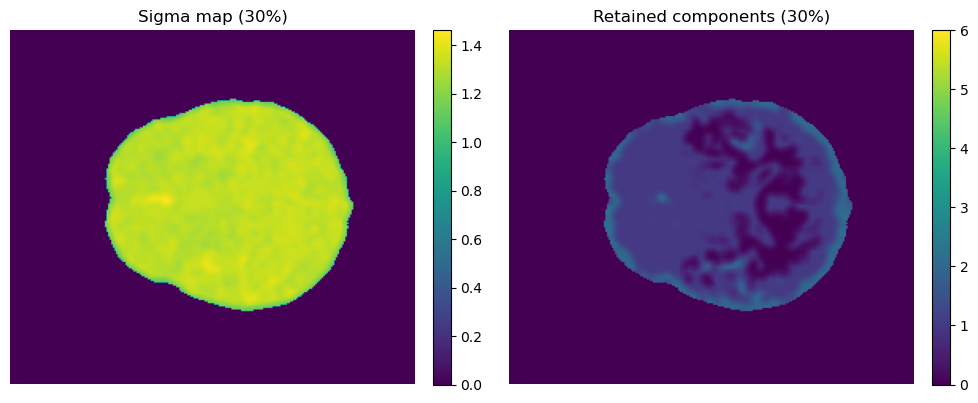

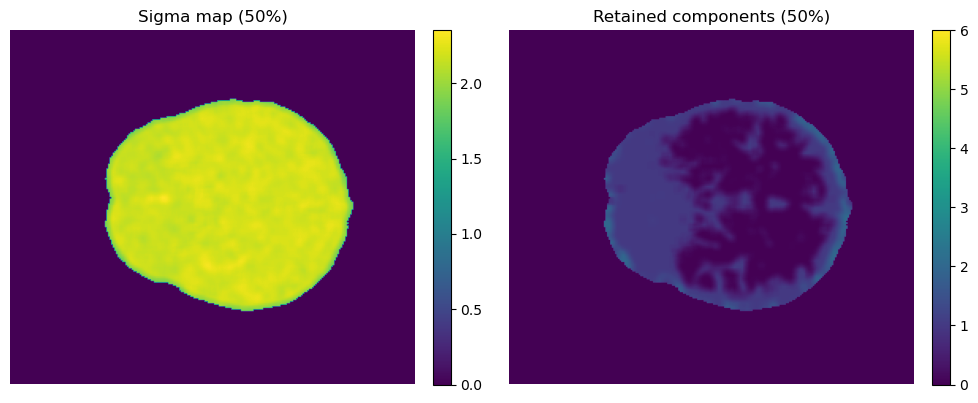

In [ ]:
slice_idx = meas_gre.shape[2] // 2

for noise_level in NOISE_LEVELS:
    sigma_map = denoised_data[noise_level]["sigma_map"]
    ncomp_map = denoised_data[noise_level]["ncomp_map"]

    fig, ax = plt.subplots(
        1,
        2,
        figsize=(10, 4)
    )

    im0 = ax[0].imshow(
        sigma_map[:, :, slice_idx].T,
        origin="lower"
    )
    ax[0].set_title(f"Sigma map ({noise_level}%)")
    ax[0].axis("off")
    plt.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04)

    im1 = ax[1].imshow(
        ncomp_map[:, :, slice_idx].T,
        origin="lower",
        vmin=0,
        vmax=meas_gre.shape[-1]
    )
    ax[1].set_title(f"Retained components ({noise_level}%)")
    ax[1].axis("off")
    plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


### 7. 메모리 정리


In [ ]:
del noisy_datasets
del denoised_data

gc.collect()

print("메모리 정리 완료")


메모리 정리 완료
